In [119]:
# enums.py
BYBIT_KLINE_PATH = "C:/Users/wklee/Desktop/WKLee/FBA/Capstone/fba-capstone/data/bybit_data_collection/kline/BTCUSDT/60/"
BINANCE_KLINE_PATH = "C:/Users/wklee/Desktop/WKLee/FBA/Capstone/fba-capstone/data/binance_data_collection/data/spot/daily/klines/BTCUSDT/1h/"

In [139]:
# main.py
import os 
import gzip
import zipfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

def load_binance_kline():
    binance_files = os.listdir(BINANCE_KLINE_PATH)
    dflist = [read_binance_kline(BINANCE_KLINE_PATH + file_name) for file_name in binance_files]
    
    df = pd.concat(dflist)
    df['time'] = np.where(df['time'] // 10**13 != 0,
                          (df['time'] / 1000).astype(int), 
                          df['time'])
    df['time'] = pd.to_datetime(df['time'], unit='ms')
    df['return'] = df['close'] / df['open'] - 1 
    return df

def load_bybit_kline():
    bybit_files = os.listdir(BYBIT_KLINE_PATH)
    dflist = [read_bybit_kline(BYBIT_KLINE_PATH + file_name) for file_name in bybit_files]
    df = pd.concat(dflist)
    df['time'] = pd.to_datetime(df['time']) - pd.offsets.Hour(3) # Adjust 'time' in order to make sure UTC+0
    df['return'] = df['close'] / df['open'] - 1 
    return df

def read_bybit_kline(path):
    with gzip.open(path) as file:
        df = pd.read_csv(file, header= None)
        df.columns = ['time', 'open', 'high', 'low', 'close', 'volume']
        return df

def read_binance_kline(path):
    with zipfile.ZipFile(path) as zf:
        with zf.open(zf.namelist()[0]) as file:
            df = pd.read_csv(file, header=None)
            df = df.iloc[:, :6]
            df.columns = ['time', 'open', 'high', 'low', 'close', 'volume']
            return df

In [140]:
bybit_df = load_bybit_kline()
binance_df = load_binance_kline()

Text(0.5, 1.0, 'Return of Bybit Exchange w.r.t. trading hour')

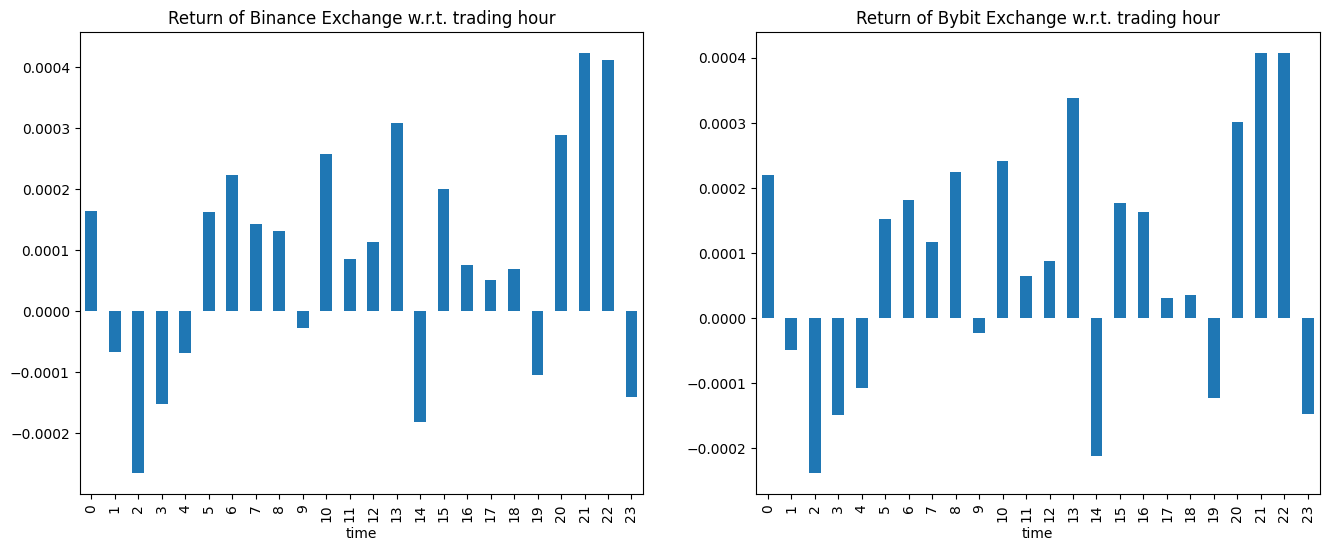

In [147]:
fig, ax = plt.subplots(1, 2, figsize=(16, 6))

binance_df.groupby(binance_df['time'].dt.hour)['return'].mean().plot(kind='bar', ax=ax[0])
ax[0].set_title("Return of Binance Exchange w.r.t. trading hour")

bybit_df['return'] = bybit_df['close'] / bybit_df['open'] - 1 
bybit_df.groupby(bybit_df['time'].dt.hour)['return'].mean().plot(kind='bar', ax=ax[1])
ax[1].set_title("Return of Bybit Exchange w.r.t. trading hour")

Text(0.5, 1.0, 'volume of Bybit Exchange w.r.t. trading hour')

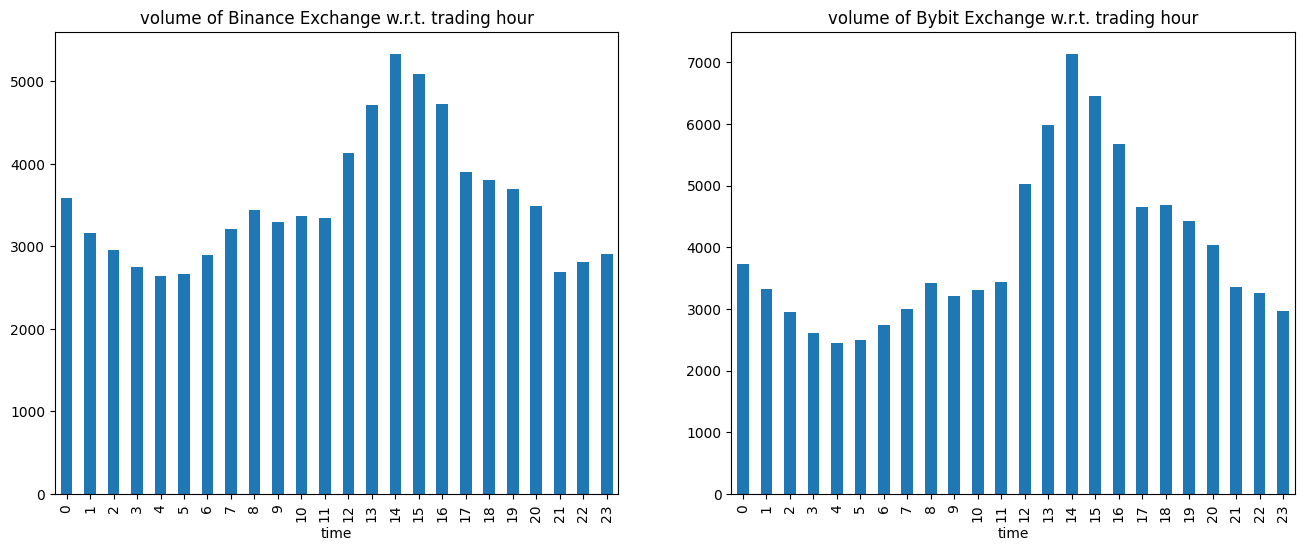

In [181]:
fig, ax = plt.subplots(1, 2, figsize=(16, 6))

binance_df.groupby(binance_df['time'].dt.hour)['volume'].mean().plot(kind='bar', ax=ax[0])
ax[0].set_title("volume of Binance Exchange w.r.t. trading hour")

bybit_df.groupby(bybit_df['time'].dt.hour)['volume'].mean().plot(kind='bar', ax=ax[1])
ax[1].set_title("volume of Bybit Exchange w.r.t. trading hour")

In [161]:
def print_basic_performance(df):
    total_rtn = df['cumrtn'].iloc[-1] - 1
    mdd = ((df['cumrtn'] / df['cumrtn'].cummax()) - 1).min()
    volatility = df['return'].std() * np.sqrt(len(df))
    sharpe = total_rtn / volatility
    print(f"RETURN: {total_rtn:.4f} | VOL: {volatility:.4f} | SHARPE: {sharpe:.4f} | MDD: {mdd:.4f}")

def get_hourly_divided_df(df, hours=[21, 22]):
    golden_hour = df[df['time'].dt.hour.isin(hours)]
    golden_hour = golden_hour.set_index('time')[['return']]
    golden_hour = golden_hour.groupby(golden_hour.index.date).apply(lambda x: (1+x).prod() - 1)
    golden_hour['cumrtn'] = (golden_hour['return'] + 1).cumprod()

    other_hour = df[~df['time'].dt.hour.isin(hours)]
    other_hour = other_hour.set_index('time')[['return']]
    other_hour = other_hour.groupby(other_hour.index.date).apply(lambda x: (1+x).prod() - 1)
    other_hour['cumrtn'] = (other_hour['return'] + 1).cumprod()
    
    return golden_hour, other_hour

In [178]:
golden_binance, other_binance = get_hourly_divided_df(binance_df)
golden_bybit, other_bybit = get_hourly_divided_df(bybit_df)

<Axes: title={'center': 'Cumm. Return of BTC on Bybit 00~22 hour.'}>

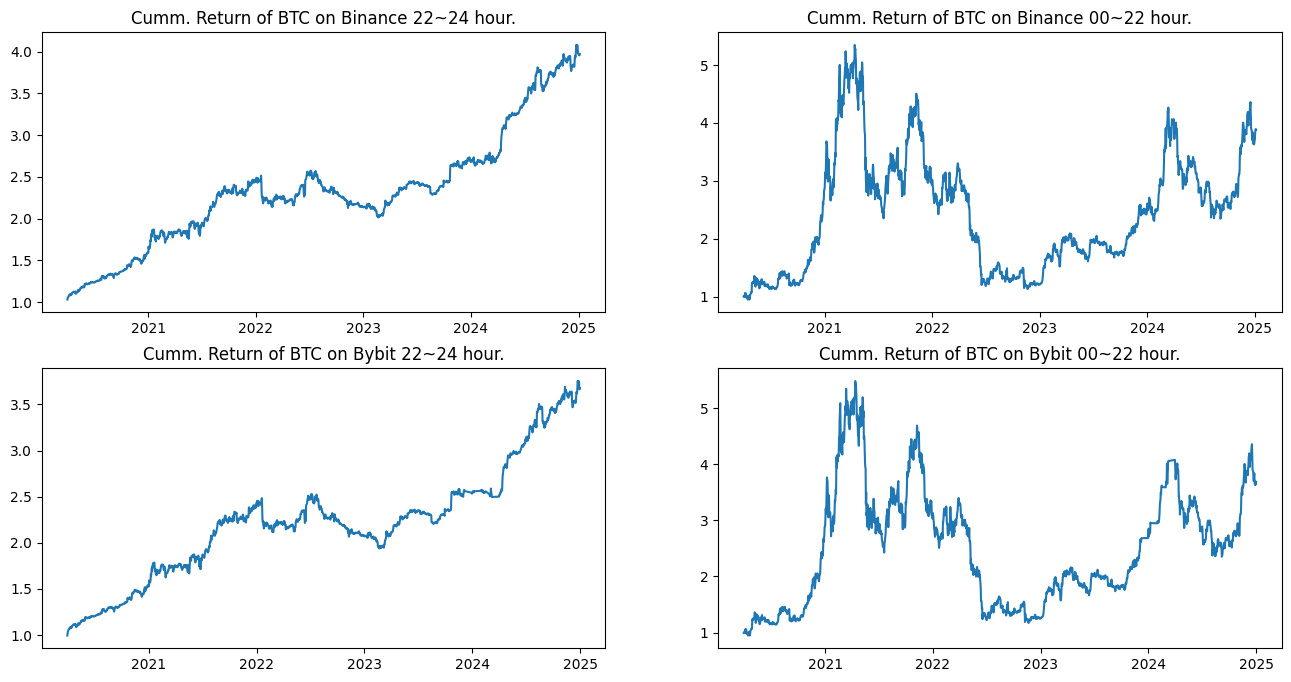

In [179]:
fig, ax = plt.subplots(2, 2, figsize=(16, 8))

golden_binance['cumrtn'].plot(ax=ax[0][0], title="Cumm. Return of BTC on Binance 22~24 hour.")
other_binance['cumrtn'].plot(ax=ax[0][1], title="Cumm. Return of BTC on Binance 00~22 hour.")
golden_bybit['cumrtn'].plot(ax=ax[1][0], title="Cumm. Return of BTC on Bybit 22~24 hour.")
other_bybit['cumrtn'].plot(ax=ax[1][1], title="Cumm. Return of BTC on Bybit 00~22 hour.")

In [180]:
print("Performance of BTC on Exchange at different time. (1st: 22:00-23:59, 2nd: 00-21:59)")
print_basic_performance(golden_binance)
print_basic_performance(other_binance)
print("-" * 60)
print_basic_performance(golden_bybit)
print_basic_performance(other_bybit)

Performance of BTC on Exchange at different time. (1st: 22:00-23:59, 2nd: 00-21:59)
RETURN: 2.9727 | VOL: 0.3760 | SHARPE: 7.9061 | MDD: -0.2180
RETURN: 2.8821 | VOL: 1.2826 | SHARPE: 2.2471 | MDD: -0.7885
------------------------------------------------------------
RETURN: 2.6752 | VOL: 0.3723 | SHARPE: 7.1864 | MDD: -0.2335
RETURN: 2.6879 | VOL: 1.2589 | SHARPE: 2.1352 | MDD: -0.7862


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from data.fetcher import TickData

tickdata = TickData()

def draw_hourly_trade(df, **figargs):    
    hourly_df = df.groupby(df['utc_time'].dt.to_period("1h")).agg({'price': ['first', 'max', 'min', 'last'], 
                                                                   "qty": ['sum', 'count']})
    hourly_df.columns = ['open', 'high', 'low', 'close', 'volume', 'count']
    hourly_mean = hourly_df.groupby(hourly_df.index.strftime("%H"))['count'].mean()
    hourly_mean.plot(kind='bar', **figargs)

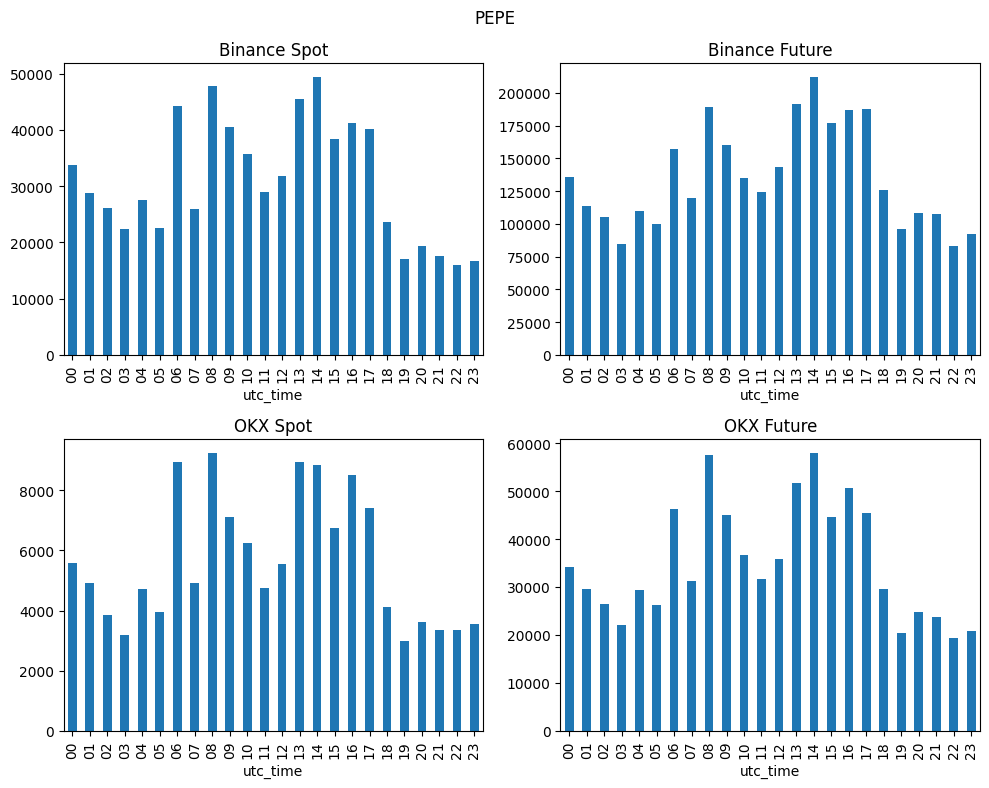

In [12]:
fig, ax = plt.subplots(2, 2, figsize=(10, 8))

bn_spot = "PEPEUSDT"
bn_future = "1000PEPEUSDT"
okx_spot = "PEPE-USDT"
okx_future = "PEPE-USDT-SWAP"

tickdata.fetch_binance("2024-12-25", "2025-01-05", 'spot', bn_spot)
tickdata.fetch_binance("2024-12-25", "2025-01-05", 'future', bn_future)
tickdata.fetch_okx("2024-12-25", "2025-01-05", 'spot', okx_spot)
tickdata.fetch_okx("2024-12-25", "2025-01-05", 'future', okx_future)

draw_hourly_trade(tickdata[f"binance_spot_{bn_spot}"], ax=ax[0][0])
draw_hourly_trade(tickdata[f"binance_future_{bn_future}"], ax=ax[0][1])
draw_hourly_trade(tickdata[f"okx_spot_{okx_spot}"], ax=ax[1][0])
draw_hourly_trade(tickdata[f"okx_future_{okx_future}"], ax=ax[1][1])

ax[0][0].set_title("Binance Spot")
ax[0][1].set_title("Binance Future")
ax[1][0].set_title("OKX Spot")
ax[1][1].set_title("OKX Future")

plt.suptitle("PEPE")
plt.tight_layout()

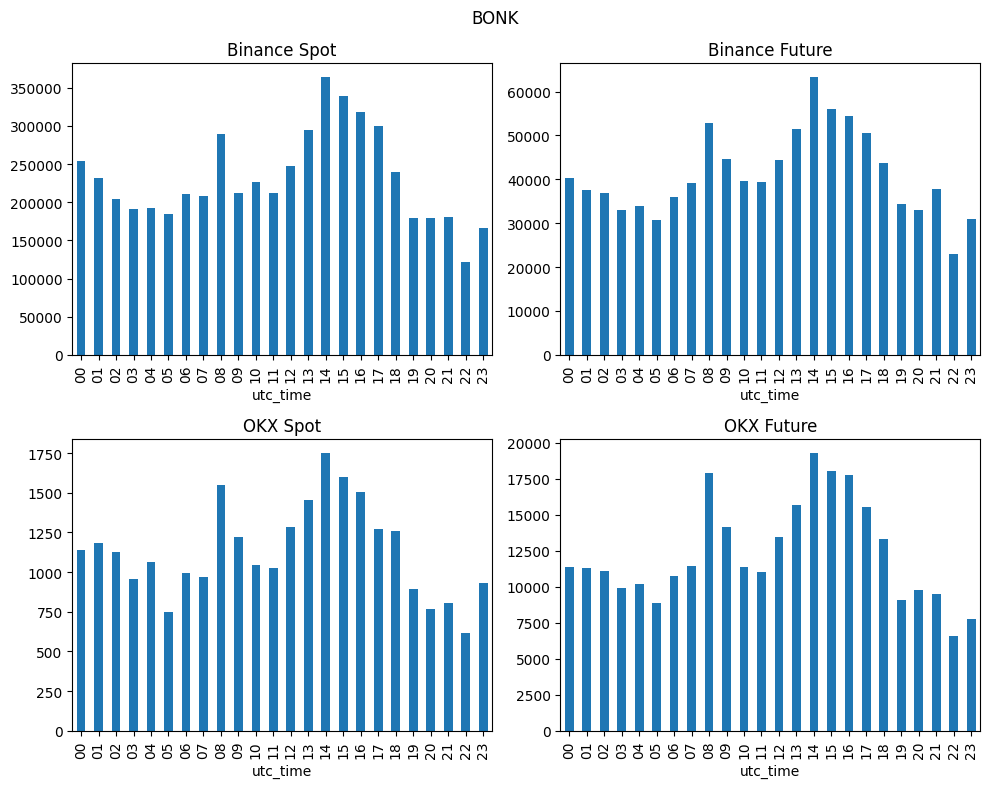

In [13]:
fig, ax = plt.subplots(2, 2, figsize=(10, 8))

bn_spot = "BONKUSDT"
bn_future = "1000BONKUSDT"
okx_spot = "BONK-USDT"
okx_future = "BONK-USDT-SWAP"

tickdata.fetch_binance("2024-12-25", "2025-01-05", 'spot', bn_spot)
tickdata.fetch_binance("2024-12-25", "2025-01-05", 'future', bn_future)
tickdata.fetch_okx("2024-12-25", "2025-01-05", 'spot', okx_spot)
tickdata.fetch_okx("2024-12-25", "2025-01-05", 'future', okx_future)

draw_hourly_trade(tickdata[f"binance_spot_{bn_spot}"], ax=ax[0][0])
draw_hourly_trade(tickdata[f"binance_future_{bn_future}"], ax=ax[0][1])
draw_hourly_trade(tickdata[f"okx_spot_{okx_spot}"], ax=ax[1][0])
draw_hourly_trade(tickdata[f"okx_future_{okx_future}"], ax=ax[1][1])

ax[0][0].set_title("Binance Spot")
ax[0][1].set_title("Binance Future")
ax[1][0].set_title("OKX Spot")
ax[1][1].set_title("OKX Future")

plt.suptitle("BONK")
plt.tight_layout()

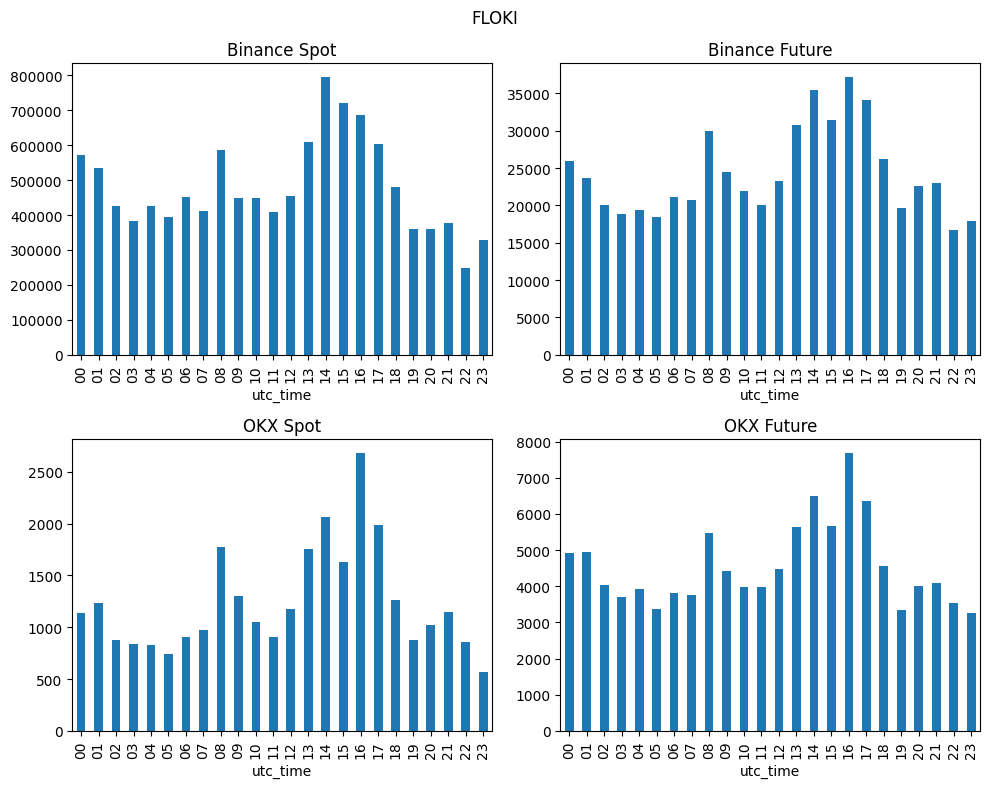

In [14]:
fig, ax = plt.subplots(2, 2, figsize=(10, 8))

bn_spot = "FLOKIUSDT"
bn_future = "1000FLOKIUSDT"
okx_spot = "FLOKI-USDT"
okx_future = "FLOKI-USDT-SWAP"

tickdata.fetch_binance("2024-12-25", "2025-01-05", 'spot', bn_spot)
tickdata.fetch_binance("2024-12-25", "2025-01-05", 'future', bn_future)
tickdata.fetch_okx("2024-12-25", "2025-01-05", 'spot', okx_spot)
tickdata.fetch_okx("2024-12-25", "2025-01-05", 'future', okx_future)

draw_hourly_trade(tickdata[f"binance_spot_{bn_spot}"], ax=ax[0][0])
draw_hourly_trade(tickdata[f"binance_future_{bn_future}"], ax=ax[0][1])
draw_hourly_trade(tickdata[f"okx_spot_{okx_spot}"], ax=ax[1][0])
draw_hourly_trade(tickdata[f"okx_future_{okx_future}"], ax=ax[1][1])

ax[0][0].set_title("Binance Spot")
ax[0][1].set_title("Binance Future")
ax[1][0].set_title("OKX Spot")
ax[1][1].set_title("OKX Future")

plt.suptitle("FLOKI")
plt.tight_layout()

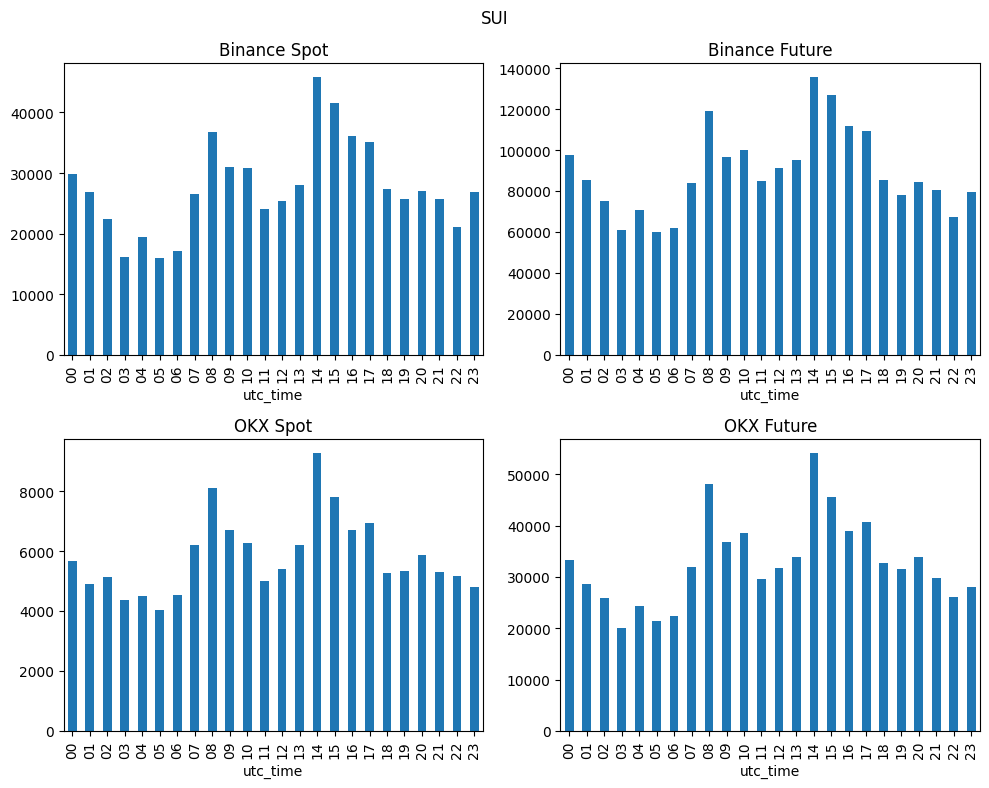

In [15]:
fig, ax = plt.subplots(2, 2, figsize=(10, 8))

bn_spot = "SUIUSDT"
bn_future = "SUIUSDT"
okx_spot = "SUI-USDT"
okx_future = "SUI-USDT-SWAP"

tickdata.fetch_binance("2024-12-25", "2025-01-05", 'spot', bn_spot)
tickdata.fetch_binance("2024-12-25", "2025-01-05", 'future', bn_future)
tickdata.fetch_okx("2024-12-25", "2025-01-05", 'spot', okx_spot)
tickdata.fetch_okx("2024-12-25", "2025-01-05", 'future', okx_future)

draw_hourly_trade(tickdata[f"binance_spot_{bn_spot}"], ax=ax[0][0])
draw_hourly_trade(tickdata[f"binance_future_{bn_future}"], ax=ax[0][1])
draw_hourly_trade(tickdata[f"okx_spot_{okx_spot}"], ax=ax[1][0])
draw_hourly_trade(tickdata[f"okx_future_{okx_future}"], ax=ax[1][1])

ax[0][0].set_title("Binance Spot")
ax[0][1].set_title("Binance Future")
ax[1][0].set_title("OKX Spot")
ax[1][1].set_title("OKX Future")

plt.suptitle("SUI")
plt.tight_layout()

[1/12] Fetching Data from APTUSDT-trades-2024-12-25.zip...
[2/12] Fetching Data from APTUSDT-trades-2024-12-26.zip...
[3/12] Fetching Data from APTUSDT-trades-2024-12-27.zip...
[4/12] Fetching Data from APTUSDT-trades-2024-12-28.zip...
[5/12] Fetching Data from APTUSDT-trades-2024-12-29.zip...
[6/12] Fetching Data from APTUSDT-trades-2024-12-30.zip...
[7/12] Fetching Data from APTUSDT-trades-2024-12-31.zip...
[8/12] Fetching Data from APTUSDT-trades-2025-01-01.zip...
[9/12] Fetching Data from APTUSDT-trades-2025-01-02.zip...
[10/12] Fetching Data from APTUSDT-trades-2025-01-03.zip...
[11/12] Fetching Data from APTUSDT-trades-2025-01-04.zip...
[12/12] Fetching Data from APTUSDT-trades-2025-01-05.zip...
[1/12] Fetching Data from APTUSDT-trades-2024-12-25.zip...
[2/12] Fetching Data from APTUSDT-trades-2024-12-26.zip...
[3/12] Fetching Data from APTUSDT-trades-2024-12-27.zip...
[4/12] Fetching Data from APTUSDT-trades-2024-12-28.zip...
[5/12] Fetching Data from APTUSDT-trades-2024-12-29.z

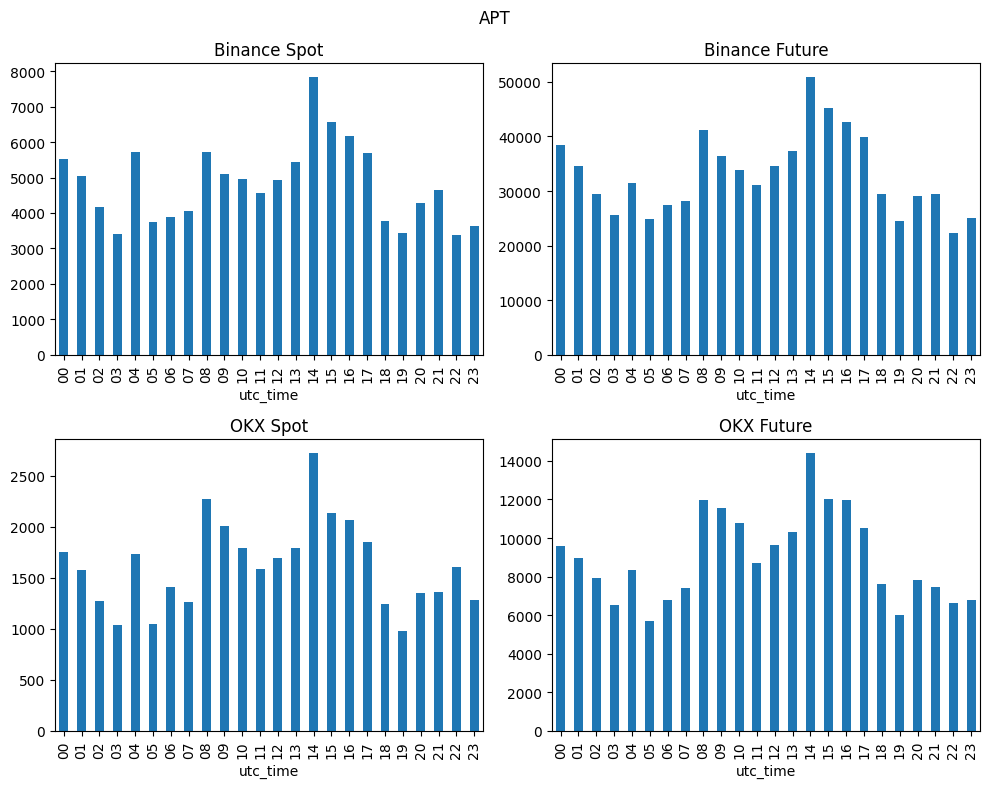

In [2]:
fig, ax = plt.subplots(2, 2, figsize=(10, 8))

bn_spot = "APTUSDT"
bn_future = "APTUSDT"
okx_spot = "APT-USDT"
okx_future = "APT-USDT-SWAP"

tickdata.fetch_binance("2024-12-25", "2025-01-05", 'spot', bn_spot)
tickdata.fetch_binance("2024-12-25", "2025-01-05", 'future', bn_future)
tickdata.fetch_okx("2024-12-25", "2025-01-05", 'spot', okx_spot)
tickdata.fetch_okx("2024-12-25", "2025-01-05", 'future', okx_future)

draw_hourly_trade(tickdata[f"binance_spot_{bn_spot}"], ax=ax[0][0])
draw_hourly_trade(tickdata[f"binance_future_{bn_future}"], ax=ax[0][1])
draw_hourly_trade(tickdata[f"okx_spot_{okx_spot}"], ax=ax[1][0])
draw_hourly_trade(tickdata[f"okx_future_{okx_future}"], ax=ax[1][1])

ax[0][0].set_title("Binance Spot")
ax[0][1].set_title("Binance Future")
ax[1][0].set_title("OKX Spot")
ax[1][1].set_title("OKX Future")

plt.suptitle("APT")
plt.tight_layout()

[1/12] Fetching Data from SOLUSDT-trades-2024-12-25.zip...
[2/12] Fetching Data from SOLUSDT-trades-2024-12-26.zip...
[3/12] Fetching Data from SOLUSDT-trades-2024-12-27.zip...
[4/12] Fetching Data from SOLUSDT-trades-2024-12-28.zip...
[5/12] Fetching Data from SOLUSDT-trades-2024-12-29.zip...
[6/12] Fetching Data from SOLUSDT-trades-2024-12-30.zip...
[7/12] Fetching Data from SOLUSDT-trades-2024-12-31.zip...
[8/12] Fetching Data from SOLUSDT-trades-2025-01-01.zip...
[9/12] Fetching Data from SOLUSDT-trades-2025-01-02.zip...
[10/12] Fetching Data from SOLUSDT-trades-2025-01-03.zip...
[11/12] Fetching Data from SOLUSDT-trades-2025-01-04.zip...
[12/12] Fetching Data from SOLUSDT-trades-2025-01-05.zip...
[1/12] Fetching Data from SOLUSDT-trades-2024-12-25.zip...
[2/12] Fetching Data from SOLUSDT-trades-2024-12-26.zip...
[3/12] Fetching Data from SOLUSDT-trades-2024-12-27.zip...
[4/12] Fetching Data from SOLUSDT-trades-2024-12-28.zip...
[5/12] Fetching Data from SOLUSDT-trades-2024-12-29.z

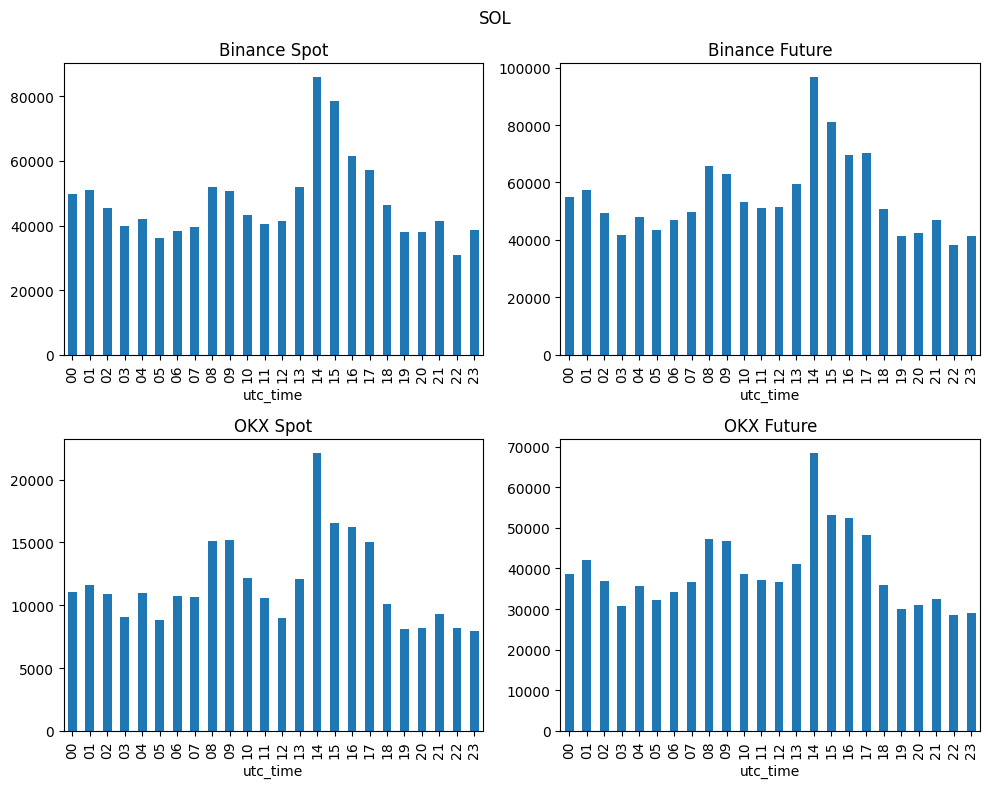

In [3]:
fig, ax = plt.subplots(2, 2, figsize=(10, 8))

bn_spot = "SOLUSDT"
bn_future = "SOLUSDT"
okx_spot = "SOL-USDT"
okx_future = "SOL-USDT-SWAP"

tickdata.fetch_binance("2024-12-25", "2025-01-05", 'spot', bn_spot)
tickdata.fetch_binance("2024-12-25", "2025-01-05", 'future', bn_future)
tickdata.fetch_okx("2024-12-25", "2025-01-05", 'spot', okx_spot)
tickdata.fetch_okx("2024-12-25", "2025-01-05", 'future', okx_future)

draw_hourly_trade(tickdata[f"binance_spot_{bn_spot}"], ax=ax[0][0])
draw_hourly_trade(tickdata[f"binance_future_{bn_future}"], ax=ax[0][1])
draw_hourly_trade(tickdata[f"okx_spot_{okx_spot}"], ax=ax[1][0])
draw_hourly_trade(tickdata[f"okx_future_{okx_future}"], ax=ax[1][1])

ax[0][0].set_title("Binance Spot")
ax[0][1].set_title("Binance Future")
ax[1][0].set_title("OKX Spot")
ax[1][1].set_title("OKX Future")

plt.suptitle("SOL")
plt.tight_layout()

In [22]:
def draw_hourly_dt(df, **figargs):    
    df= df.copy()
    df['dt'] = df['time'].diff()
    hourly_df = df.groupby(df['utc_time'].dt.to_period("1h"))[['dt']].mean()
    hourly_mean = hourly_df.groupby(hourly_df.index.strftime("%H"))['dt'].mean() / 1000
    return hourly_mean

In [ ]:
['BTC', '', '', '', '', '', '']

In [54]:
bn_spot = "BTCUSDT"
bn_future = "BTCUSDT"
okx_spot = "BTC-USDT"
okx_future = "BTC-USDT-SWAP"

tickdata = TickData()
tickdata.fetch_binance("2024-12-25", "2025-01-05", 'spot', bn_spot)
tickdata.fetch_binance("2024-12-25", "2025-01-05", 'future', bn_future)
tickdata.fetch_okx("2024-12-25", "2025-01-05", 'spot', okx_spot)
tickdata.fetch_okx("2024-12-25", "2025-01-05", 'future', okx_future)

with open("hourly_corr.txt", 'a') as f:
    for key in tickdata.keys():
        data = ",".join(draw_hourly_dt(tickdata[key]).astype(str).values)
        f.write(f"{key},{data}\n")

[1/12] Fetching Data from BTCUSDT-trades-2024-12-25.zip...
[2/12] Fetching Data from BTCUSDT-trades-2024-12-26.zip...
[3/12] Fetching Data from BTCUSDT-trades-2024-12-27.zip...
[4/12] Fetching Data from BTCUSDT-trades-2024-12-28.zip...
[5/12] Fetching Data from BTCUSDT-trades-2024-12-29.zip...
[6/12] Fetching Data from BTCUSDT-trades-2024-12-30.zip...
[7/12] Fetching Data from BTCUSDT-trades-2024-12-31.zip...
[8/12] Fetching Data from BTCUSDT-trades-2025-01-01.zip...
[9/12] Fetching Data from BTCUSDT-trades-2025-01-02.zip...
[10/12] Fetching Data from BTCUSDT-trades-2025-01-03.zip...
[11/12] Fetching Data from BTCUSDT-trades-2025-01-04.zip...
[12/12] Fetching Data from BTCUSDT-trades-2025-01-05.zip...
[1/12] Fetching Data from BTCUSDT-trades-2024-12-25.zip...
[2/12] Fetching Data from BTCUSDT-trades-2024-12-26.zip...
[3/12] Fetching Data from BTCUSDT-trades-2024-12-27.zip...
[4/12] Fetching Data from BTCUSDT-trades-2024-12-28.zip...
[5/12] Fetching Data from BTCUSDT-trades-2024-12-29.z

In [67]:
df = pd.read_csv(f"hourly_corr.txt", header=None)

df.columns = range(-1, 24)
df = df.set_index(-1)

Text(0.5, 1.0, 'Transaction time delta of all Pairs w.r.t. Trading Hour')

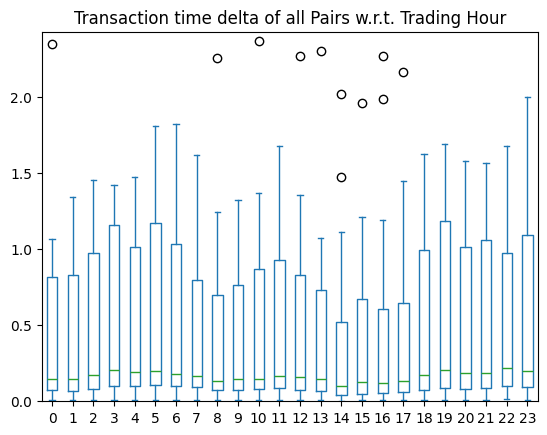

In [80]:
df.plot(kind='box', ylim = (0, 2.43))
plt.title("Transaction time delta of all Pairs w.r.t. Trading Hour")

Text(0.5, 1.0, 'Average Transaction time delta of all Pairs w.r.t. Trading Hour')

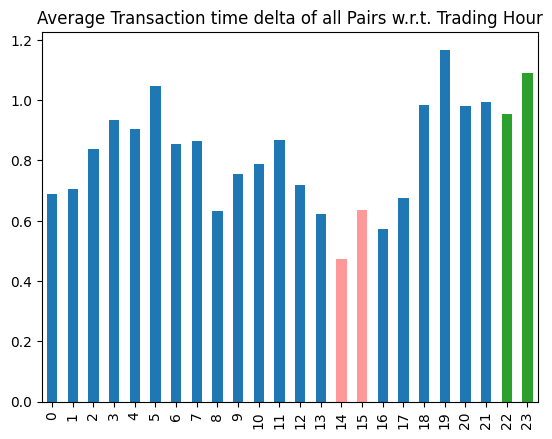

In [81]:
colors = []
for i in df.columns:
    if i in [14, 15]:  # 연한 빨간색
        colors.append('#FF9999')  # 연한 빨간색 (Hex)
    elif i in [22, 23]:  # 초록색
        colors.append('tab:green')
    else:  # 기본 파란색
        colors.append('tab:blue')

df.mean(axis=0).plot(kind='bar', color=colors)
plt.title("Average Transaction time delta of all Pairs w.r.t. Trading Hour")

In [87]:
pair_result_summary = df.mean(axis=1).to_frame()
pair_result_summary.index.name = None
pair_result_summary.columns = ['delta_time']

In [89]:
import numpy as np
import matplotlib.pyplot as plt

import os
import matplotlib.pyplot as plt
import pandas as pd

def read_txt(path):
    with open(path) as f:
        data = [l.strip().split(",") for l in f.readlines()]
        df = pd.DataFrame(data, columns=["lag", "corr"])
        df['corr'] = df['corr'].astype(float)
        return df.set_index('lag')

# 정렬을 위한 기준 함수 정의
def parse_side(side):
    parts = side.split("-")
    exchange, trade_type, ticker = parts[0], parts[1], parts[2].replace("1000", "").replace("USDT", "")
    return exchange, trade_type, ticker

def sort_key(key):
    left, right = key.split(" & ")
    # Extract ticker, exchange, and type from each side

    # Define custom sorting orders
    ticker_order = {"BTC": 0, "ETH": 1, "SOL":2, "OM":3, "PEPE":4, "FLOKI": 5, "BONK": 6, "SUI": 7, "APT": 8}
    exchange_order = {"binance": 0, "bybit": 1, "okx": 2}
    trade_type_order = {"spot": 0, "future": 1}

    # Parse left and right
    left_exchange, left_type, left_ticker = parse_side(left)
    right_exchange, right_type, right_ticker = parse_side(right)

    # Return tuple for sorting
    return (
        ticker_order.get(left_ticker, float("inf")),
        exchange_order.get(left_exchange, float("inf")),
        trade_type_order.get(left_type, float("inf")),
        ticker_order.get(right_ticker, float("inf")),
        exchange_order.get(right_exchange, float("inf")),
        trade_type_order.get(right_type, float("inf")),
    )
    

In [165]:
hy_data_dir = "data/HayashiYoshidaTicker"

file_names = os.listdir(hy_data_dir)
data_paths = [os.path.join(hy_data_dir, filename) for filename in file_names]

corr_dict= {}
for path in data_paths:
    df = read_txt(path)
    name = path.split("_")[-3:-1]
    corr_dict[" & ".join(name)] = df

# 키를 정렬하여 새 딕셔너리 생성
sorted_keys = sorted(corr_dict.keys(), key=sort_key)
sorted_dict = {key: corr_dict[key] for key in sorted_keys}

tickers = ['BTC', 'ETH', "SOL", "OM", 'PEPE', 'FLOKI', "BONK"]

final_sorted_dict = {ticker: {key: sorted_dict[key] for key in sorted_dict.keys() if parse_side(key.split(" & ")[0])[-1] == ticker} for ticker in tickers}

In [166]:
def parses(key, side):
    splited = key.split(" & ")[side].split("-")
    return "_".join(splited[:2]) +"_" + "-".join(splited[2:])
    
def get_llr(df):
    return df[df.index.astype(int) < 0]['corr'].sum() / df[df.index.astype(int) > 0]['corr'].sum()

major_list = []
for key in ['BTC', 'ETH', 'SOL']:
    for k, v in final_sorted_dict[key].items():
        major_list.append([parses(k, 0), parses(k, 1), get_llr(v)])

In [167]:

major_list = []
for key in ['BTC', 'ETH', 'SOL']:
    for k, v in final_sorted_dict[key].items():
        major_list.append([parses(k, 0), parses(k, 1), get_llr(v)])
        
llr_df = pd.DataFrame(major_list)
llr_df = llr_df.merge(pair_result_summary, how='left', left_on=0, right_index=True)
llr_df = llr_df.merge(pair_result_summary, how='left', left_on=1, right_index=True, suffixes=("_left", "_right"))

# future - spot case
fs_df = llr_df[llr_df[0].str.contains('future') & llr_df[1].str.contains('spot') |\
    llr_df[0].str.contains('spot') & llr_df[1].str.contains('future')].copy(
        
    )

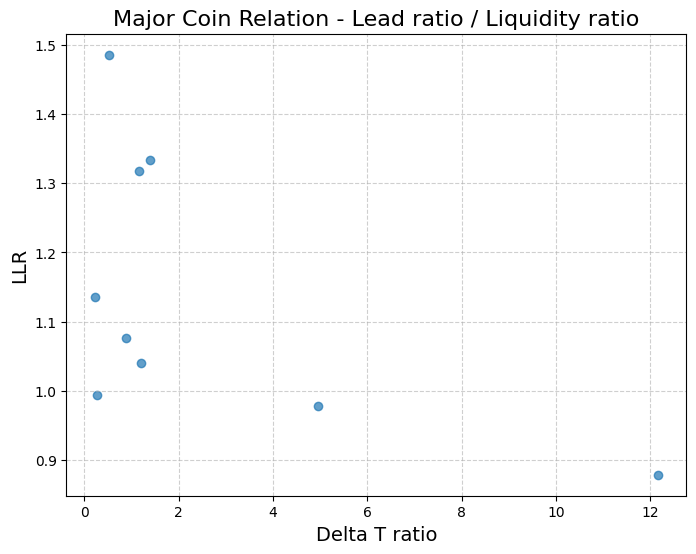

In [168]:
plt.figure(figsize=(8, 6))
plt.scatter(fs_df['delta_time_right'] / fs_df['delta_time_left'], fs_df[2], color='tab:blue', alpha=0.7)

# 그래프 꾸미기
plt.title('Major Coin Relation - Lead ratio / Liquidity ratio', fontsize=16)
plt.xlabel('Delta T ratio', fontsize=14)
plt.ylabel('LLR', fontsize=14)
plt.grid(True, linestyle='--', alpha=0.6)

In [174]:
major_list = []
for key in ['PEPE', 'BONK']:
    for k, v in final_sorted_dict[key].items():
        major_list.append([parses(k, 0), parses(k, 1), get_llr(v)])
        
llr_df = pd.DataFrame(major_list)
llr_df = llr_df.merge(pair_result_summary, how='left', left_on=0, right_index=True)
llr_df = llr_df.merge(pair_result_summary, how='left', left_on=1, right_index=True, suffixes=("_left", "_right"))

# future - spot case
fs_df = llr_df[llr_df[0].str.contains('future') & llr_df[1].str.contains('spot') |\
    llr_df[0].str.contains('spot') & llr_df[1].str.contains('future')].copy(    
    )
    

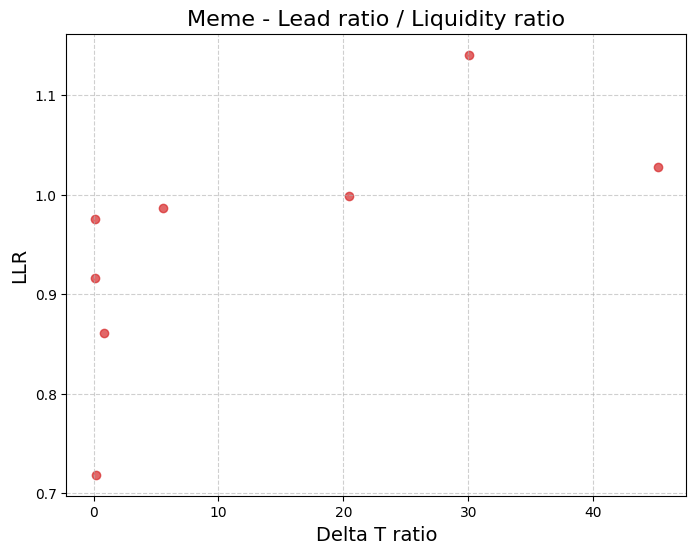

In [175]:
plt.figure(figsize=(8, 6))
plt.scatter(fs_df['delta_time_right'] / fs_df['delta_time_left'], fs_df[2], color='tab:red', alpha=0.7)

# 그래프 꾸미기
plt.title('Meme - Lead ratio / Liquidity ratio', fontsize=16)
plt.xlabel('Delta T ratio', fontsize=14)
plt.ylabel('LLR', fontsize=14)
plt.grid(True, linestyle='--', alpha=0.6)

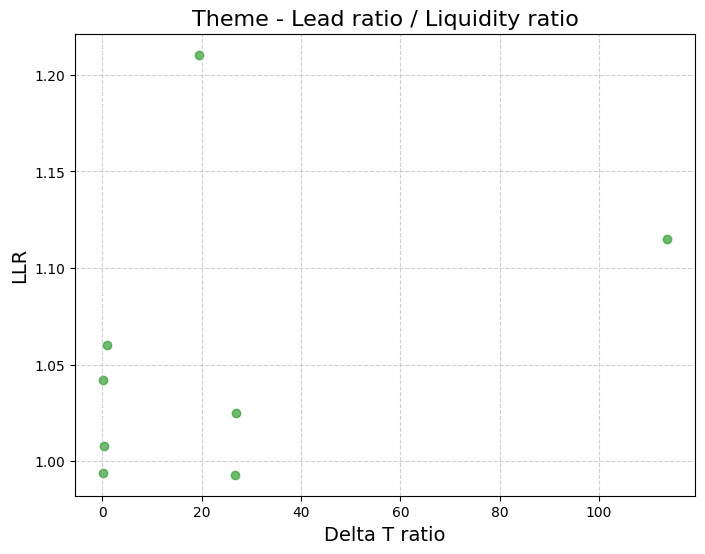

In [176]:
major_list = []
for key in ['OM', 'FLOKI']:
    for k, v in final_sorted_dict[key].items():
        major_list.append([parses(k, 0), parses(k, 1), get_llr(v)])
        
llr_df = pd.DataFrame(major_list)
llr_df = llr_df.merge(pair_result_summary, how='left', left_on=0, right_index=True)
llr_df = llr_df.merge(pair_result_summary, how='left', left_on=1, right_index=True, suffixes=("_left", "_right"))

# future - spot case
fs_df = llr_df[llr_df[0].str.contains('future') & llr_df[1].str.contains('spot') |\
    llr_df[0].str.contains('spot') & llr_df[1].str.contains('future')].copy(    
    )
    
    
plt.figure(figsize=(8, 6))
plt.scatter(fs_df['delta_time_right'] / fs_df['delta_time_left'], fs_df[2], color='tab:green', alpha=0.7)

# 그래프 꾸미기
plt.title('Theme - Lead ratio / Liquidity ratio', fontsize=16)
plt.xlabel('Delta T ratio', fontsize=14)
plt.ylabel('LLR', fontsize=14)
plt.grid(True, linestyle='--', alpha=0.6)